# Isolated Word Recognition - Demonstration & Benchmark
Trực quan hóa đặc trưng âm thanh và đối sánh thực nghiệm giữa 3 kiến trúc: **CNN**, **Vanilla RNN**, và **BiRNN**.

In [15]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import soundfile as sf
import torch

from src import LogMelExtractor

%matplotlib inline
Path("assets").mkdir(exist_ok=True)

### 1. Trực quan hóa đặc trưng âm thanh (Waveform & Log-Mel Spectrogram)

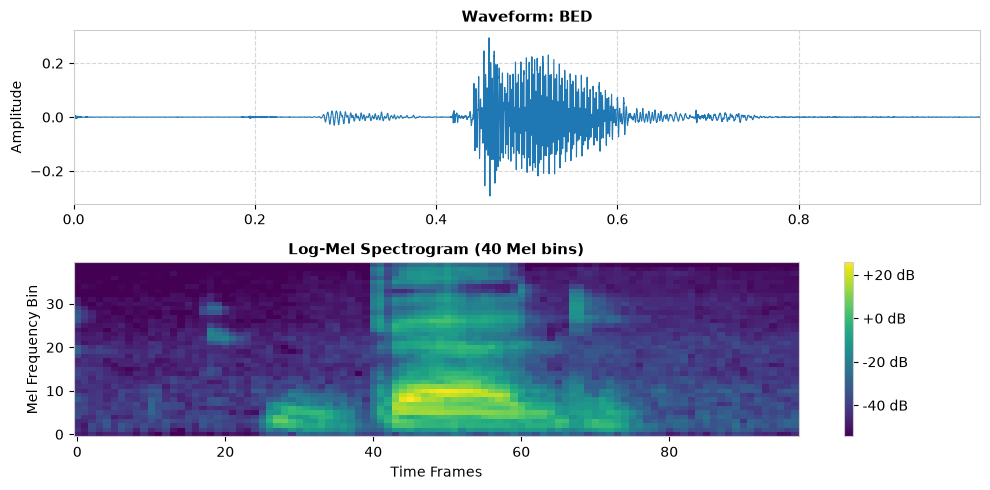

In [16]:
def plot_audio_features(audio_path: str, extractor=None, title: str = "Audio Analysis"):
    path = Path(audio_path)
    if path.is_dir():
        path = next(path.glob("*.wav"))
    if extractor is None:
        extractor = LogMelExtractor()

    data, sr = sf.read(str(path), dtype="float32")
    waveform = torch.from_numpy(data).unsqueeze(0)
    if waveform.dim() > 2:
        waveform = waveform.mean(dim=0, keepdim=True)

    with torch.no_grad():
        mel_spec = extractor(waveform).squeeze(0).cpu().numpy()

    fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=False)

    # Waveform
    t = [i / sr for i in range(len(data))]
    axes[0].plot(t, data, color="#1f77b4", linewidth=0.8)
    axes[0].set_title(f"Waveform: {title}", fontsize=11, fontweight="bold")
    axes[0].set_ylabel("Amplitude")
    axes[0].set_xlim([0, t[-1]])
    axes[0].grid(True, linestyle="--", alpha=0.5)

    # Log-Mel Spectrogram
    im = axes[1].imshow(mel_spec, aspect="auto", origin="lower", cmap="viridis")
    axes[1].set_title("Log-Mel Spectrogram (40 Mel bins)", fontsize=11, fontweight="bold")
    axes[1].set_xlabel("Time Frames")
    axes[1].set_ylabel("Mel Frequency Bin")
    fig.colorbar(im, ax=axes[1], format="%+2.0f dB")

    plt.tight_layout()
    plt.show()

# Trực quan hóa mẫu từ "bed"
plot_audio_features("data/bed/0a7c2a8d_nohash_0.wav", title="BED")

### 2. Đường cong học tập (Learning Curves)

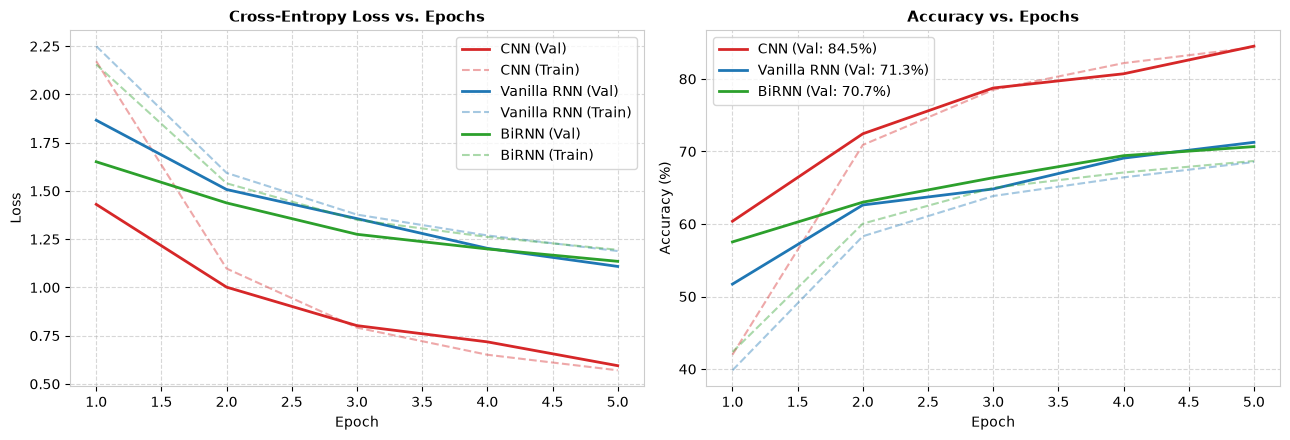

In [17]:
histories = {
    "CNN": {
        "params": 97635,
        "train_loss": [2.1718, 1.0976, 0.7917, 0.6511, 0.5706],
        "val_loss":   [1.4304, 1.0014, 0.8020, 0.7179, 0.5945],
        "train_acc":  [41.98,  70.90,  78.50,  82.18,  84.36],
        "val_acc":    [60.38,  72.44,  78.75,  80.71,  84.52],
        "test_loss":  0.6200,
        "test_acc":   82.39,
        "epoch_times": [50.18, 47.60, 49.78, 52.76, 52.52],
    },
    "Vanilla RNN": {
        "params": 97979,
        "train_loss": [2.2503, 1.5934, 1.3773, 1.2694, 1.1886],
        "val_loss":   [1.8664, 1.5073, 1.3565, 1.2026, 1.1088],
        "train_acc":  [39.83,  58.31,  63.86,  66.43,  68.54],
        "val_acc":    [51.71,  62.62,  64.83,  69.08,  71.26],
        "test_loss":  1.1723,
        "test_acc":   69.59,
        "epoch_times": [50.91, 49.81, 49.67, 50.05, 48.91],
    },
    "BiRNN": {
        "params": 97601,
        "train_loss": [2.1554, 1.5394, 1.3501, 1.2615, 1.1951],
        "val_loss":   [1.6511, 1.4379, 1.2753, 1.1993, 1.1352],
        "train_acc":  [42.35,  60.05,  64.99,  67.10,  68.69],
        "val_acc":    [57.53,  63.01,  66.38,  69.42,  70.67],
        "test_loss":  1.1953,
        "test_acc":   69.12,
        "epoch_times": [52.20, 51.46, 50.49, 50.46, 50.29],
    }
}

epochs = range(1, 6)
colors = {"CNN": "#d62728", "Vanilla RNN": "#1f77b4", "BiRNN": "#2ca02c"}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# 1. Loss
for name, h in histories.items():
    c = colors[name]
    ax1.plot(epochs, h["val_loss"], label=f"{name} (Val)", color=c, linewidth=2)
    ax1.plot(epochs, h["train_loss"], linestyle="--", color=c, alpha=0.4, label=f"{name} (Train)")
ax1.set_title("Cross-Entropy Loss vs. Epochs", fontsize=11, fontweight="bold")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.5)

# 2. Accuracy
for name, h in histories.items():
    c = colors[name]
    ax2.plot(epochs, h["val_acc"], label=f"{name} (Val: {max(h['val_acc']):.1f}%)", color=c, linewidth=2)
    ax2.plot(epochs, h["train_acc"], linestyle="--", color=c, alpha=0.4)
ax2.set_title("Accuracy vs. Epochs", fontsize=11, fontweight="bold")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")
ax2.legend()
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("assets/learning_curves.png", dpi=300)
plt.show()

### 3. Đối sánh hiệu năng Test Accuracy & Tốc độ huấn luyện

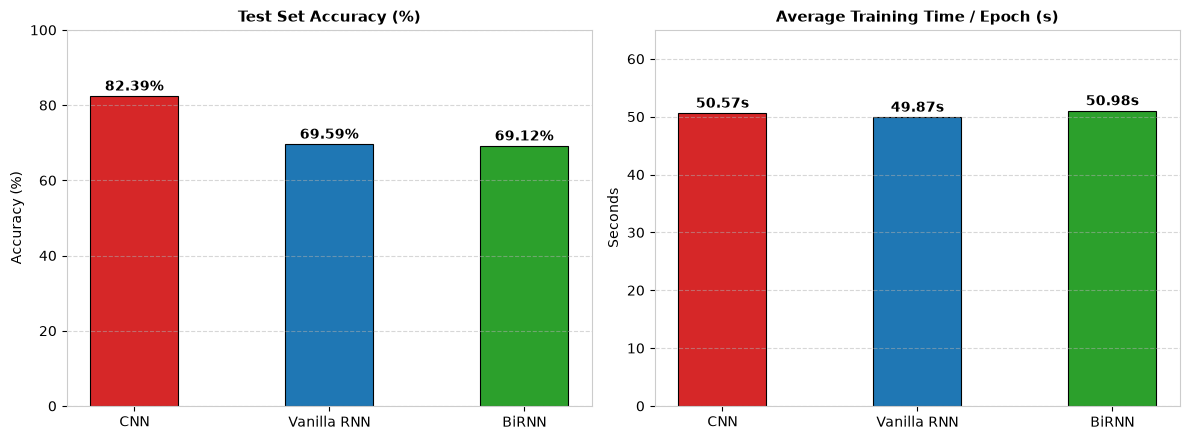

In [18]:
names = list(histories.keys())
test_accs = [histories[m]["test_acc"] for m in names]
avg_times = [np.mean(histories[m]["epoch_times"]) for m in names]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# Test Accuracy
bars1 = ax1.bar(names, test_accs, color=[colors[n] for n in names], width=0.45, edgecolor="black", linewidth=0.8)
ax1.set_title("Test Set Accuracy (%)", fontsize=11, fontweight="bold")
ax1.set_ylabel("Accuracy (%)")
ax1.set_ylim([0, 100])
ax1.grid(axis="y", linestyle="--", alpha=0.5)
for bar in bars1:
    y = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width() / 2, y + 1.5, f"{y:.2f}%", ha="center", fontweight="bold")

# Training Time
bars2 = ax2.bar(names, avg_times, color=[colors[n] for n in names], width=0.45, edgecolor="black", linewidth=0.8)
ax2.set_title("Average Training Time / Epoch (s)", fontsize=11, fontweight="bold")
ax2.set_ylabel("Seconds")
ax2.set_ylim([0, 65])
ax2.grid(axis="y", linestyle="--", alpha=0.5)
for bar in bars2:
    y = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2, y + 1.0, f"{y:.2f}s", ha="center", fontweight="bold")

plt.tight_layout()
plt.savefig("assets/benchmark_comparison.png", dpi=300)
plt.show()

### 4. Bảng tổng kết số liệu Benchmark

In [19]:
print("=" * 70)
print(f"{'Model':<14} | {'Params':<10} | {'Best Val Acc':<14} | {'Test Acc':<10} | {'Test Loss':<10}")
print("-" * 70)
for name, h in histories.items():
    print(f"{name:<14} | {h['params']:<10,} | {max(h['val_acc']):<13.2f}% | {h['test_acc']:<9.2f}% | {h['test_loss']:<10.4f}")
print("=" * 70)

Model          | Params     | Best Val Acc   | Test Acc   | Test Loss 
----------------------------------------------------------------------
CNN            | 97,635     | 84.52        % | 82.39    % | 0.6200    
Vanilla RNN    | 97,979     | 71.26        % | 69.59    % | 1.1723    
BiRNN          | 97,601     | 70.67        % | 69.12    % | 1.1953    
